In [3]:
# Installıng kaggle library
!pip install -q kaggle

!mkdir -p ~/.kaggle
!cp /content/drive/MyDrive/GROUP21_CENG313/kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

%cd /content/drive/MyDrive/GROUP21_CENG313/data
!kaggle competitions download -c birdclef-2025
!unzip -q birdclef-2025.zip -d birdclef-2025
!rm birdclef-2025.zip

/content/drive/MyDrive/GROUP21_CENG313/data
100% 11.5G/11.5G [09:26<00:00, 21.8MB/s]

/content/drive/MyDrive/GROUP21_CENG313


In [3]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Set working directory to the persistent project folder
project_path = '/content/drive/MyDrive/GROUP21_CENG313'
os.chdir(project_path)

Mounted at /content/drive


In [4]:
# Çalışma dizinine geri dön
%cd /content/drive/MyDrive/GROUP21_CENG313

/content


Total number of samples: 28564
Total number of unique species: 206


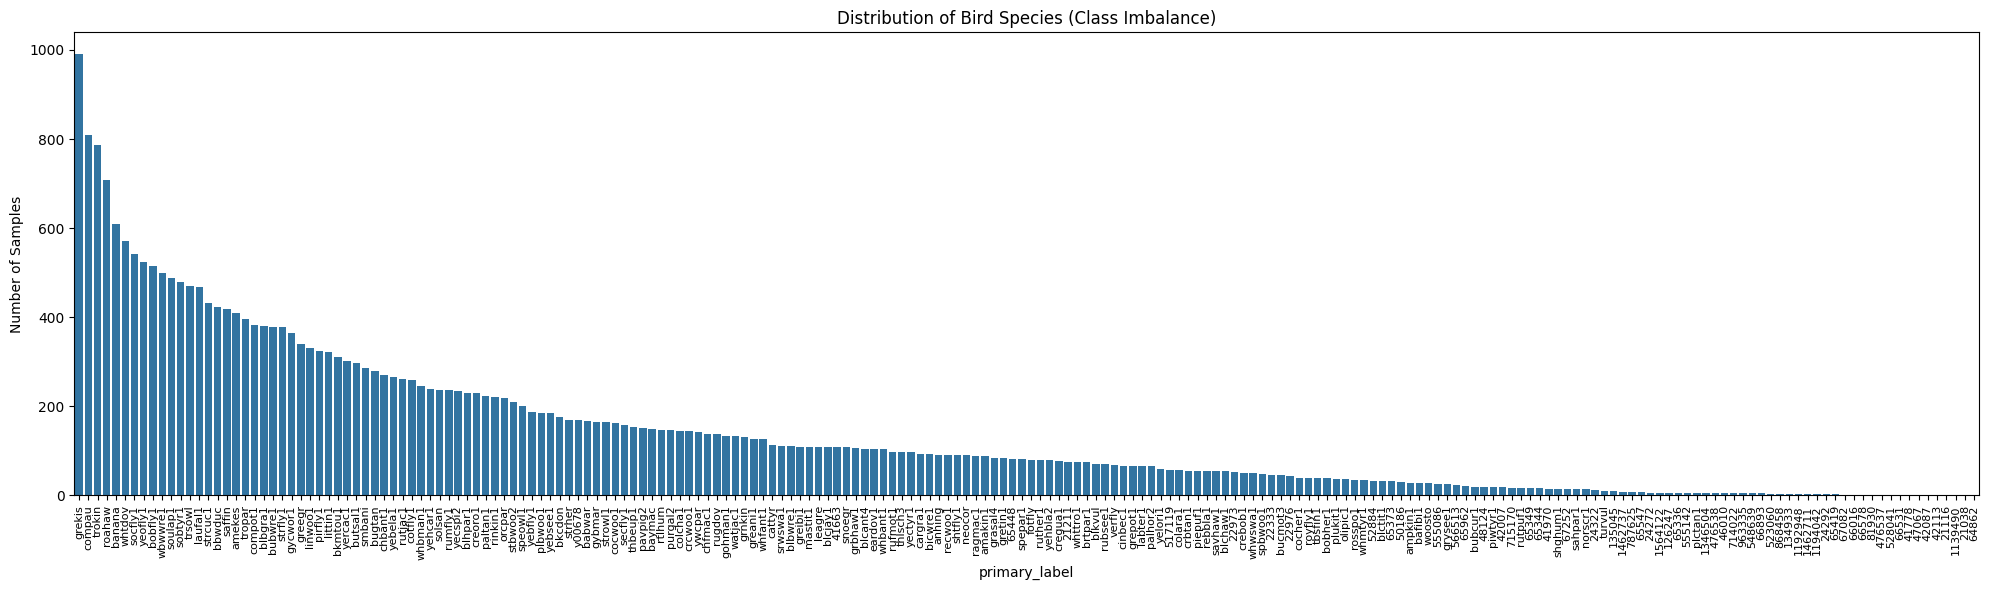

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Define file paths
data_dir = 'data/birdclef-2025'
metadata_path = os.path.join(data_dir, 'train.csv')

# Load and inspect metadata
df = pd.read_csv(metadata_path)
print(f"Total number of samples: {len(df)}")
print(f"Total number of unique species: {df['primary_label'].nunique()}")

# Plot class distribution
plt.figure(figsize=(20, 6))
sns.countplot(data=df, x='primary_label', order=df['primary_label'].value_counts().index)
plt.xticks(rotation=90, fontsize=8)
plt.title('Distribution of Bird Species (Class Imbalance)')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

Plotting spectrogram for species: 1564122


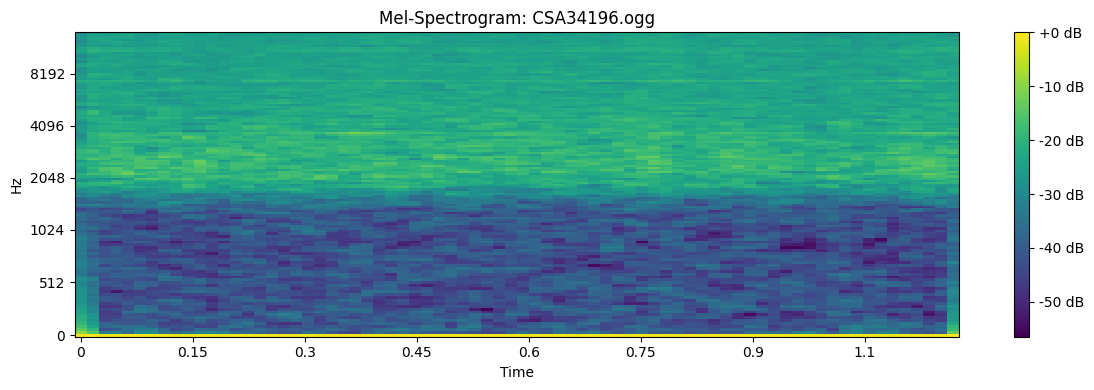

In [6]:
import os
from src.data import plot_mel_spectrogram

# Get a sample audio file path from the dataframe
sample_row = df.iloc[45]
sample_audio_path = os.path.join(data_dir, 'train_audio', sample_row['filename'])

# Call the function from src/data.py
print(f"Plotting spectrogram for species: {sample_row['primary_label']}")
plot_mel_spectrogram(sample_audio_path)

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# Assume 'df' is the metadata dataframe loaded in the previous steps
encoder = LabelEncoder()
df['label_id'] = encoder.fit_transform(df['primary_label'])
num_classes = len(encoder.classes_)

# Stratified split to maintain class distribution in the validation set
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label_id']
)

print(f"Total classes: {num_classes}")
print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")

Total classes: 206
Training samples: 22851
Validation samples: 5713


Using device: cpu
Error loading data/birdclef-2025/train_audio/yercac1/XC387883.ogg: Failed to create AudioDecoder for data/birdclef-2025/train_audio/yercac1/XC387883.ogg: SingleStreamDecoder, /__w/torchcodec/torchcodec/meta-pytorch/torchcodec/src/torchcodec/_core/SingleStreamDecoder.cpp:51, Could not open input file: data/birdclef-2025/train_audio/yercac1/XC387883.ogg No such file or directory
Waveform batch shape: torch.Size([16, 1, 160000])
Mel-spectrogram batch shape: torch.Size([16, 1, 128, 313])


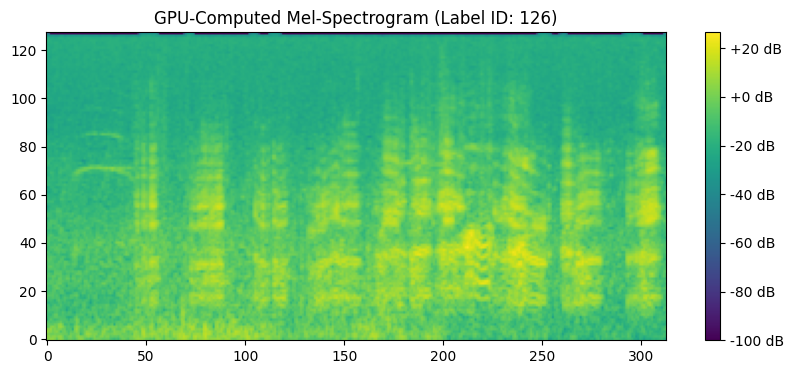

Error loading data/birdclef-2025/train_audio/yeofly1/XC254002.ogg: Failed to create AudioDecoder for data/birdclef-2025/train_audio/yeofly1/XC254002.ogg: SingleStreamDecoder, /__w/torchcodec/torchcodec/meta-pytorch/torchcodec/src/torchcodec/_core/SingleStreamDecoder.cpp:51, Could not open input file: data/birdclef-2025/train_audio/yeofly1/XC254002.ogg No such file or directory
Error loading data/birdclef-2025/train_audio/yeofly1/XC920619.ogg: Failed to create AudioDecoder for data/birdclef-2025/train_audio/yeofly1/XC920619.ogg: SingleStreamDecoder, /__w/torchcodec/torchcodec/meta-pytorch/torchcodec/src/torchcodec/_core/SingleStreamDecoder.cpp:51, Could not open input file: data/birdclef-2025/train_audio/yeofly1/XC920619.ogg No such file or directory


In [10]:
import torch
import torchaudio.transforms as T
from torch.utils.data import DataLoader
from src.data import BirdCLEFAudioDataset
import matplotlib.pyplot as plt

# Ensure GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create Dataset and DataLoader
train_dataset = BirdCLEFAudioDataset(train_df, audio_dir='data/birdclef-2025/train_audio')
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)

# Define GPU-based MelSpectrogram transformations
mel_transform = T.MelSpectrogram(
    sample_rate=32000,
    n_fft=2048,
    hop_length=512,
    n_mels=128
).to(device)

amplitude_to_db = T.AmplitudeToDB().to(device)

# Fetch a batch and apply transformations on GPU
for waveforms, labels in train_loader:
    waveforms = waveforms.to(device)
    labels = labels.to(device)

    # 1. Convert waveforms to Mel-spectrograms on GPU
    mels = mel_transform(waveforms)

    # 2. Convert to Decibel scale on GPU
    mels_db = amplitude_to_db(mels)

    print(f"Waveform batch shape: {waveforms.shape}")
    print(f"Mel-spectrogram batch shape: {mels_db.shape}")

    # Plot the first item in the batch
    plt.figure(figsize=(10, 4))
    plt.imshow(mels_db[0, 0].cpu().numpy(), aspect='auto', origin='lower', cmap='viridis')
    plt.title(f"GPU-Computed Mel-Spectrogram (Label ID: {labels[0].item()})")
    plt.colorbar(format='%+2.0f dB')
    plt.show()
    break